In [471]:
import os, sys

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    sys.path.append(module_path)
sys.path.append(os.getcwd())

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection, LineCollection, Collection
from matplotlib.path import Path
from mpl_toolkits.mplot3d import Axes3D

from scipy.stats import pearsonr, spearmanr
import math
import torch
import gpytorch
from matplotlib import pyplot as plt
import plotly.graph_objects as go

import seaborn as sns
from scipy.spatial import ConvexHull, convex_hull_plot_2d

import pandas as pd
import pickle as pkl

import trimesh
import gymnasium as gym

from argparse import Namespace

from lap.sac_airl_lap_liver import Actor, SoftQNetwork
from lap.ppo_airl_lap_liver import Agent

#from lap.sac_gail_lap_liver import Actor
from irl.airl import AIRLDiscriminator
from irl.gail import GAILDiscriminator
from envs.env_lap_liver import plt_sphere
from irl.utils import load_lap_demos

import ot

from texttable import Texttable
import latextable

#%matplotlib inline
%matplotlib widget
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
data_dict = {}
for f in os.listdir('.'):
    if 'npy' in f:
        data_dict[f] = np.load(f)
   
df1 = pd.read_excel('DiagnosticLaparoscopy_UnknownPathology_2021-18-10--14-48-56.xls')
df2 = pd.read_excel('DiagnosticLaparoscopy_UnknownPathology_2021-18-10--14-48-57.xls')

df1_filtered = df1[df1['Total score']>100]
df2_filtered = df2[df2['Total score']>100]

df1.keys()

Index(['Section name', 'Scene name', 'User name:', 'User session', 'Report ID',
       'Report date', 'Exercise completed', 'Total score', 'Report items:',
       'Simulation overview', 'Simulation overview score',
       'Procedure time sec', 'Procedure time sec score', 'Economy',
       'Economy score', 'Camera path length cm', 'Camera path length cm score',
       'Total instruments path length cm',
       'Total instruments path length cm score',
       'Alignment of the scope horizon %',
       'Alignment of the scope horizon % score',
       'Idle time Atraumatic Grasping Forceps %',
       'Idle time Atraumatic Grasping Forceps % score',
       'Idle time Atraumatic Grasping Forceps sec',
       'Idle time Atraumatic Grasping Forceps sec score',
       'Atraumatic Grasping Forceps path length cm',
       'Atraumatic Grasping Forceps path length cm score',
       'Idle time Suction & Irrigation Device %',
       'Idle time Suction & Irrigation Device % score',
       'Idle time S

In [10]:
def as_mesh(scene_or_mesh):
    """
    Convert a possible scene to a mesh.

    If conversion occurs, the returned mesh has only vertex and face data.
    """
    if isinstance(scene_or_mesh, trimesh.Scene):
        if len(scene_or_mesh.geometry) == 0:
            mesh = None  # empty scene
        else:
            # we lose texture information here
            mesh = trimesh.util.concatenate(
                tuple(trimesh.Trimesh(vertices=g.vertices, faces=g.faces)
                      for g in scene_or_mesh.geometry.values()))
    else:
        assert(isinstance(scene_or_mesh, trimesh.Trimesh))
        mesh = scene_or_mesh
    return mesh

def load_mesh_tri(fname, simplify_mesh=False, scale=100):

    mesh = as_mesh(trimesh.load_mesh(fname))
    mesh.apply_scale(scale)
    if simplify_mesh and 'Belly' not in f:
        mesh = mesh.simplify_quadratic_decimation(2000)

    # apply gravity shift on everything but Belly
    if 'Belly' in fname:
        return mesh.vertices, mesh
    else:
        return mesh.vertices + np.tile((0,-2,0),(mesh.vertices.shape[0],1)), mesh

obj_dict = {}
for f in os.listdir('obj'):
    if '.obj' in f:
        #obj_dict[f] = load_obj(os.path.join('obj',f))
        obj_dict[f] = load_mesh_tri(os.path.join('obj',f))



In [11]:
### evaluate based on GAIL

In [387]:
def init_actor_disc(run_folder, demos, algo='ppo', disc='gail', best=False):
    args = pkl.load(open(os.path.join(run_folder,'hparams.pkl'),'rb'))

    args = Namespace(**args)
    print(os.listdir(run_folder))

    test_env = gym.make(args.env_id, gc=args.goal_conditioning, 
                             state_spec=args.state_spec, 
                             step_size=args.step_size,
                             done_on_collision=args.done_on_collision,
                             hard_collisions=args.hard_collisions,
                             plot_meshes=args.render_meshes,
                             continuous_actions=args.continuous_actions,
                             condition_on_n_tasks_completed=args.condition_on_n_tasks_completed,
                             collision_loss=args.collision_loss,
                             vis_threshold_factor = args.vis_threshold_factor,
                             mesh_folder='../davos_data/obj/',
                             ref_demo=demos)

    if args.normalize_obs and isinstance(test_env.action_space, gym.spaces.Box):
            env = gym.wrappers.NormalizeObservation(test_env)
            env = gym.wrappers.TransformObservation(env, lambda obs: np.clip(obs, -10, 10))
    if args.clip_action and isinstance(test_env.action_space, gym.spaces.Box):
        test_env = gym.wrappers.ClipAction(test_env)

    discrete = not isinstance(test_env.action_space, gym.spaces.Box)
    if disc == 'gail':
        disc = GAILDiscriminator(test_env, args)
    else:
        disc = AIRLDiscriminator(test_env, args)
      
    if best:
        disc.load_state_dict(torch.load(os.path.join(run_folder, "best_disc.pt")))
    else:
        disc.load_state_dict(torch.load(os.path.join(run_folder, "disc.pt")))

    #disc_airl = AIRLDiscriminator(test_env, args)
    #if args.load_disc:
    #    disc_airl.load_state_dict(torch.load(os.path.join(run_folder, "disc.pt") , map_location=device))

    if algo == 'ppo':
        actor = Agent(test_env)
        if best:
            actor.load_state_dict(torch.load(os.path.join(run_folder, "best_actor.pt")))
        else:
            actor.load_state_dict(torch.load(os.path.join(run_folder, "agent.pt")))
    else: # SAC
        actor = SoftQNetwork(test_env)
        if best:
            actor.load_state_dict(torch.load(os.path.join(run_folder, "best_qf1.pt")))
        else:
            actor.load_state_dict(torch.load(os.path.join(run_folder, "qf1.pt")))       

    return actor, disc, test_env

def evaluate_traj_disc_gail(test_env, disc, item):
    total_rew = 0
    pos_t = torch.from_numpy(item)
    with torch.no_grad():
        rew_ = disc.get_reward(pos_t, ac=None)
    return torch.sum(rew_)

def evaluate_traj_disc_airl(test_env, disc, item):
    total_rew = 0
    pos_t = torch.from_numpy(item)
    with torch.no_grad():
        rew_ = disc.reward(disc.base(pos_t))

    return torch.sum(rew_)

def evaluate_traj_value_ppo(test_env, agent, item):
    total_rew = 0
    pos_t = torch.from_numpy(item)
    with torch.no_grad():
        rew_ = agent.get_value(pos_t)
    return torch.sum(rew_)

def evaluate_traj_value_sac(test_env, qf, item):
    total_rew = 0
    pos_t = torch.from_numpy(item)
    ac0 = torch.zeros_like(torch.from_numpy(test_env.action_space.sample()))
    ac_t = torch.tile(ac0, (pos_t.shape[0],1))
    with torch.no_grad():
        rew_ = qf(pos_t,ac_t)
    return torch.sum(rew_)

def eval_data(test_env, actor, disc, data_dict, algo_type='ppo', disc_type='gail', score_type='Total score'):
    # evaluate data using trained models
    gt_score = []
    predicted_score_disc = []
    predicted_score_val = []

    for i, item in df1.iterrows():
        #df1['Attachments:']
        for item_k, item_v in data_dict.items():
            if item['Attachments:'][:8] == item_k[:8]:
                idx = ((item_v[:,-1] >= 12) & (item_v[:,-1] <= 14))
                gt_score.append(item[score_type])
                if disc_type == 'gail':
                    predicted_score_disc.append(evaluate_traj_disc_gail(test_env, disc, item_v[idx,:3]).numpy())
                else:
                    predicted_score_disc.append(evaluate_traj_disc_airl(test_env, disc, item_v[idx,:3]).numpy())

                if algo_type == 'ppo':
                    predicted_score_val.append(evaluate_traj_value_ppo(test_env, actor, item_v[idx,:3]).numpy())
                else:
                    predicted_score_val.append(evaluate_traj_value_sac(test_env, actor, item_v[idx,:3]).numpy())


                #print("GT trajectory score: ", item['Total score'], "Model score:", evaluate_traj(disc_gail, item_v[idx,:3]).numpy())

    #np.corrcoef(np.array(gt_score), np.stack(predicted_score))

    gt_score_normed = gt_score/np.linalg.norm(gt_score)
    predicted_score_disc_normed = predicted_score_disc/np.linalg.norm(predicted_score_disc)
    predicted_score_val_normed = predicted_score_val/np.linalg.norm(predicted_score_val)

    # calculate ranking
    gt_sorted_idx = np.argsort(gt_score_normed)
    predicted_sorted_idx = np.argsort(predicted_score_disc_normed)
    
    return gt_score_normed, predicted_score_disc_normed, predicted_score_val_normed

def eval_data_2(test_env, total_distance_score, total_safety_score, actor, disc, data_dict, algo_type='ppo', disc_type='gail', score_type='Total score'):
    # evaluate data using trained models
    dist_score = []
    safety_score = []
    predicted_score_disc = []
    predicted_score_val = []
    
    for item_k, item_v in data_dict.items():
        dist_score.append(total_distance_score[item_k])
        safety_score.append(total_safety_score[item_k])

        # TODO: hand select the indices
        idx = ((item_v[:,-1] >= 12) & (item_v[:,-1] <= 14))
        if disc_type == 'gail':
            predicted_score_disc.append(evaluate_traj_disc_gail(test_env, disc, item_v[idx,:3]).numpy())
        else:
            predicted_score_disc.append(evaluate_traj_disc_airl(test_env, disc, item_v[idx,:3]).numpy())

        if algo_type == 'ppo':
            predicted_score_val.append(evaluate_traj_value_ppo(test_env, actor, item_v[idx,:3]).numpy())
        else:
            predicted_score_val.append(evaluate_traj_value_sac(test_env, actor, item_v[idx,:3]).numpy())
            
            
    predicted_score_disc_normed = predicted_score_disc/np.linalg.norm(predicted_score_disc)
    predicted_score_val_normed = predicted_score_val/np.linalg.norm(predicted_score_val)

    return dist_score, safety_score, predicted_score_disc_normed, predicted_score_val_normed


def compute_instrument_distance(traj_, filter_idx):
    if filter_idx is not None:
        traj = []
        for idx in filter_idx:
            traj.extend(traj_[traj_[:,-1]==idx])
    
        traj = np.array(traj)
    else:
        traj = traj_


    if len(traj) > 0:
        total_covered_distance = 0
        for point, point_ in zip(traj[:-1], traj[1:]):
            total_covered_distance += np.linalg.norm(point_[:3] - point[:3])

        #total_covered_distance -= np.linalg.norm(traj[0,:3])
        return total_covered_distance
    
    else:
        return -1

from tqdm import tqdm

## calculate safety score by 
def min_vertex_distance(mesh, point):
    d = np.linalg.norm(mesh.vertices-point,-1)
    return np.min(d)

def total_min_vertex_distance(mesh, traj):
    total_distance = 0 
    for point in traj:
        total_distance += min_vertex_distance(mesh, point[:3])
        
    return total_distance

def compute_safety_score(data_dict, test_env):
    safety_scores = {}
    for traj_k, traj_v in tqdm(data_dict.items()):
        safety_scores[traj_k] = {}
        for mesh_k,mesh_v in tqdm(test_env.meshes.items()):
            safety_scores[traj_k][mesh_k] = total_min_vertex_distance(mesh_v, traj_v)

    return safety_score
    
def shortest_path_projection(centroids):
    dists = []
    for c,c_ in zip(centroids[:-1], centroids[1:]):
        d = c_-c 
        d = d/np.linalg.norm(d)
        
        dists.append(d)

    return dists


def compute_rollouts(test_env, actor, n_episodes=10):
    policy_traj = []
    with torch.no_grad():
        for i in range(n_episodes):
            traj = []
            o,_ = test_env.reset()
            traj.append(o.reshape(1,-1))
            done = False
            while not done:
                o_t = torch.from_numpy(o)
                a, lprobs, _, val = actor.get_action_and_value(o_t.reshape(1,-1))
                o,r,t,tr,i = test_env.step(a.detach().numpy())
                traj.append(o)
                done = t or tr

            policy_traj.append(np.stack(traj))
                        
    return np.squeeze(np.concatenate(policy_traj,0))
            
def compute_sw2_distance(traj, demos):
    n = min(len(traj),len(demos))
    
    policy_atoms = np.array(traj[-n:])
    expert_atoms = np.array(demos[:n])
    
    sw2_dist = ot.sliced_wasserstein_distance(policy_atoms, expert_atoms, n_projections=500, seed=42)
    
    return sw2_dist

def compute_w2_distance(traj, demos):
    n = min(len(traj),len(demos))
    
    policy_atoms = np.array(traj[-n:])
    expert_atoms = np.array(demos[:n])
    
    
    M = ot.dist(policy_atoms, expert_atoms)
    a, b = np.ones((n,)) / n, np.ones((n,)) / n  # uniform distribution on samples
    #a, b = np.arange(n) / n, np.arange(n) / n  # uniform distribution on samples

    w2_dist = ot.emd2(a,b,M)
    
    return w2_dist

#points = np.random.randn(20,3)
#shortest_path_projection(points)
        

In [392]:
policy_traj = np.array(compute_rollouts(test_env, actor_airl___))
demos = load_lap_demos('.')['all']

w2_dist = compute_w2_distance(policy_traj, demos['obs'])
sw2_dist = compute_sw2_distance(policy_traj, demos['obs'])

print(w2_dist, sw2_dist)

Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
Task solved: LiverR

In [299]:
#run_folder = '../../runs/0803_lapliver_test/20240308_021949_590810_lap_sac_gail_lap_liver__capture-video_collision_loss_step_size_1.5_vis_threshold_factor_100_total-timesteps_500000_lip_coeff_1.0_irm_coeff_1.0/'
run_folder_sn = '../../runs/20240310_151837_087026_lap_ppo_gail_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_use_spectral_norm/'
run_folder_lip = '../../runs/20240310_152748_693024_lap_ppo_gail_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_lip_coeff_1.0/'
#run_folder_irm = '../../runs/20240309_145643_597972_lap_ppo_gail_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_500000_lip_coeff_1.0_irm_coeff_1.0/'
run_folder_irm = '../../runs/20240310_175023_136723_lap_ppo_gail_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_lip_coeff_1.0_irm_coeff_10.0/'
#run_folder_irm = '../../runs/20240312_162129_918718_lap_ppo_gail_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_irm_coeff_10.0/'

run_folder_noreg = '../../runs/20240310_175015_143202_lap_ppo_gail_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000/'

run_folder_sac_airl = '../../runs/20240312_154356_745926_lap_sac_airl_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_irm_coeff_1.0/'
run_folder_ppo_airl = '../../runs/20240312_180650_922041_lap_ppo_airl_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_lip_coeff_1.0_irm_coeff_1.0_airl_reward_type_disc/'
run_folder_ppo_airl_ = '../../runs/20240312_200543_424022_lap_ppo_airl_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_lip_coeff_1.0_irm_coeff_1.0_airl_reward_type_disc/'
run_folder_ppo_airl__ = '../../runs/20240312_200616_407035_lap_ppo_airl_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_airl_reward_type_disc/'
run_folder_ppo_airl___ = '../../runs/20240315_163723_114869_lap_ppo_airl_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_airl_reward_type_disc/'
run_folder_ppo_gail___ = '../../runs/20240315_154558_997504_lap_ppo_gail_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_use_spectral_norm/'

# TODO: get run_folder with following variants over 10 seeds: (ppo / sac), (airl/gail), (sn, irm, lip, noreg) 
# Table: (algo variants) X (corr. coef variants) X (scores) + W2 / SW2 distance 
# Plot: 3d anatomy with trajectories / shading?, correlation plots x2, histogram of trajectory subset 

demos = load_lap_demos('.')

actor_sn, disc_sn, test_env = init_actor_disc(run_folder_sn, demos)
actor_irm, disc_irm, _ = init_actor_disc(run_folder_irm, demos, best=False)
actor_lip, disc_lip, _ = init_actor_disc(run_folder_lip, demos)
actor_noreg, disc_noreg, _ = init_actor_disc(run_folder_noreg, demos)

actor_sac, disc_sac, _ = init_actor_disc(run_folder_sac_airl, demos, 'sac', 'airl', best=False)

actor_airl, disc_airl, _ = init_actor_disc(run_folder_ppo_airl, demos, 'ppo', 'airl', best=False)
actor_airl_, disc_airl_, _ = init_actor_disc(run_folder_ppo_airl_, demos, 'ppo', 'airl')
actor_airl__, disc_airl__, _ = init_actor_disc(run_folder_ppo_airl__, demos, 'ppo', 'airl')
actor_airl___, disc_airl___, test_env = init_actor_disc(run_folder_ppo_airl___, demos, 'ppo', 'airl')
actor_gail___, disc_gail___, _ = init_actor_disc(run_folder_ppo_gail___, demos, 'ppo', 'gail')


Training on best trajectories: ['35da54b1-13ac-46.npy', '76c330f6-2f84-46.npy', 'aec679a0-c4ff-45.npy', '49ee32c0-1131-46.npy', '6d30c50e-1f3d-40.npy', 'f3c535fc-462c-45.npy', '108c5fb7-1a25-4e.npy', 'fb57fbba-d1a1-44.npy', 'b07a63c2-9a3f-41.npy', 'c41f4426-15b8-4f.npy', '39ec8da5-c73b-4c.npy', '875f87e6-f333-40.npy', 'bf2d94b0-752d-4b.npy', 'd58cd27d-096a-43.npy', '0e154d8e-85d8-4c.npy', '3b1148ed-a412-46.npy', '94162bd0-275e-48.npy', 'b9e91905-4f4c-4a.npy', '57dc9e10-26bb-46.npy', '0912d4e3-7e55-4e.npy', '9c74d9ee-ab25-46.npy', '60f1f42c-7040-4f.npy', 'e3634697-a87d-4e.npy', '95446495-71d0-4d.npy', '1552c740-2f6e-43.npy', '96a0b263-f925-46.npy', '0c598c36-d179-43.npy', 'bb0c2313-1b8a-4d.npy', '74e09eeb-6c21-4a.npy', 'c8acfd67-fc86-40.npy', '099b2d16-2281-4a.npy', 'bb5ea3fb-1487-4d.npy', '59813f92-c26a-42.npy', '9891a4c6-aec7-42.npy', '5d15c99e-aa26-41.npy', 'f92c6768-aa6d-45.npy', 'e92fae79-b782-45.npy', '2d3ae66d-e5e6-49.npy', 'f5275d64-8619-4a.npy', '423f3863-03e0-40.npy', 'f340543

/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/ipywidgets/widgets/widget.py:477: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  super(Widget, self).__init__(**kwargs)


-2.3 6.9 20.3 26.5 -8.5 7.9
-15.355115 29.990376


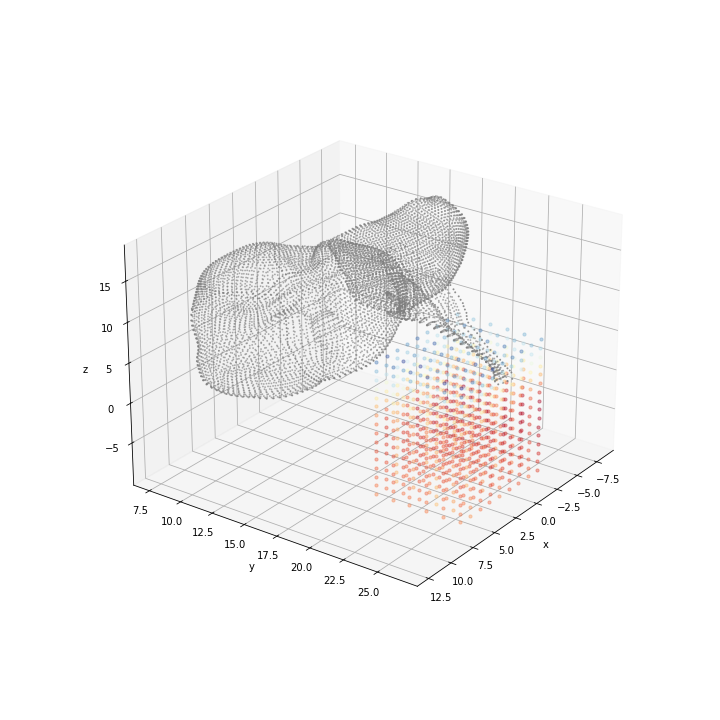

In [458]:
fig = plt.figure(figsize=[10,10])
ax = fig.add_subplot(111, projection='3d')
ax.view_init(25, 36)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')

def update_min_max(x, min_x, max_x):
    if min(x) < min_x:
        min_x = min(x)
    if max(x) > max_x:
        max_x = max(x)
    
    return min_x, max_x

def bounding_box(points):
    x_coord, y_coord, z_coord = zip(*points)

    return np.array((min(x_coord), min(y_coord), min(z_coord))), np.array((max(x_coord), max(y_coord), max(z_coord)))

def bounding_sphere(points):
    bb_min, bb_max = bounding_box(points)
    bb_center = 0.5*(bb_max-bb_min)
    radius = max(np.linalg.norm(bb_min-bb_center), np.linalg.norm(bb_max-bb_center))
    
    return bb_center, radius

for i, k in enumerate(['LiverRight.obj', 'LiverLeft.obj', 'Falciform.obj']):
    v = obj_dict[k]
    ax.scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2],s=0.8, c='gray', alpha=0.5)

#bb_points = []
max_cnt = 10
cnt = 0
min_x, max_x = 100,-100
min_y, max_y = 100,-100
min_z, max_z = 100,-100

# filter data to correspond to top demos based on which evaluation mesh grid is built
filter_name_list = []
filter_name_list.extend([item[:8] for item in df1[df1['Total score'] >= 145]['Attachments:']])
filter_name_list.extend([item[:8] for item in df2[df2['Total score'] >= 145]['Attachments:']])

filtered_dict = {}
for k,v in data_dict.items():
    filter_flag = (k[:8] in filter_name_list)

    if 'npy' in k and filter_flag:
        filtered_dict[k] = v
        
plot_traj = False
for j, (item_k, item_v) in enumerate(filtered_dict.items()):
    idx = ((item_v[:,-1] >= 12) & (item_v[:,-1] <= 14))
    if plot_traj:
        ax.scatter(item_v[idx,0],item_v[idx,1],item_v[idx,2], s=1, alpha=0.4)
    
    min_x, max_x = update_min_max(item_v[idx,0], min_x, max_x)
    min_y, max_y = update_min_max(item_v[idx,1], min_y, max_y)
    min_z, max_z = update_min_max(item_v[idx,2], min_z, max_z)

#    bb_points.extend(item_v[idx,:3])
    if j>max_cnt:
        break

print(min_x, max_x, min_y, max_y, min_z, max_z)

scaling_factor = 1
x_ = np.linspace(min_x, max_x, int(np.abs(max_x-min_x)*scaling_factor))
y_ = np.linspace(min_y, max_y, int(np.abs(max_y-min_y)*scaling_factor))
z_ = np.linspace(min_z, max_z, int(np.abs(max_z-min_z)*scaling_factor))

mesh = np.array(np.meshgrid(x_, y_, z_)).reshape(3,-1).T
batch = torch.from_numpy(mesh.astype(np.float32))
with torch.no_grad():
    rew = disc_airl___.reward(disc_airl___.base(batch)).detach().numpy()

rew = rew.reshape(len(x_),len(y_),len(z_),1)
rew_norm = np.linalg.norm(rew)

print(np.min(rew), np.max(rew))

cm = matplotlib.colormaps['RdYlBu']
for i in np.arange(len(x_)):
    for j in np.arange(len(y_)):
        for k in np.arange(len(z_)):
    #rew_color = cm(1.*rew[i,j,k]/rew_norm)
            im = ax.scatter3D(x_[i],y_[j],z_[k],c=rew[i,j,k], vmin=-15, vmax=30, s=10, alpha=0.4, cmap=cm)
#batch_size = 1000
#rews = []
#for i in range(int(len(mesh)/batch_size)):
#    if (i+1)*batch_size > len(mesh):
#        bs = len(mesh)-(i+1)*batch_size
#    else:
#        bs = (i+1)*batch_size
        
#    batch = torch.from_numpy(mesh[i:bs].astype(np.float32))
#    print(batch.shape)
#    with torch.no_grad():
#        rew = disc_airl___.reward(disc_airl___.base(batch))
#        rews.append(rew)       
#rews = torch.stack(rews)
#print(rews.shape)


#import miniball
#print(miniball.get_bounding_ball(np.array(bb_points),epsilon=1e-1))
#print(bounding_sphere(bb_points))

#%matplotlib inline
#fig.colorbar(im, ax)
plt.show()

### TODO:
- Find some evaluation ground truth metric which makes sense (ray projection + target ball occupancy / l2 norm to ray? Bc we eval on incomplete traj
- Try enhancing position features with distance to (all) anatomies -> safety features
- Try training on more targets?
- Compute W2 distance to target based on 10 rollouts! (load policy and sample using test_env)

### evaluate trajectory data and compute corr. coeffs against different ground truth scores given by simulator

### evaluate trajectory data and compute corr. coeffs against different ground truth scores computed separately

/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/ipywidgets/widgets/widget.py:477: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  super(Widget, self).__init__(**kwargs)
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/ipywidgets/widgets/widget.py:477: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  super(Widget, self).__init__(**kwargs)
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/ipywidgets/widgets/widget.py:477: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
__init__() missing 1 required positional argument: 'canvas'
This is depreca

>> Discriminator scores
Texttable Output:
+-----------+-----------+----------+----------+----------+----------+----------+
|   Model   |  Pearson  | Pearson  | Spearman | Pearson  | Wilcoxon | Wilcoxon |
|           |    CC     | p-Value  |    CC    | p-Value  |    CC    | p-Value  |
+===========+===========+==========+==========+==========+==========+==========+
| gail_sn_1 |   0.710   |  0.000   |  0.761   |  0.000   |  6.854   |  0.000   |
| (Reward)  |           |          |          |          |          |          |
+-----------+-----------+----------+----------+----------+----------+----------+
| gail_irm  |   0.763   |  0.000   |  0.762   |  0.000   |  2.092   |  0.036   |
| (Reward)  |           |          |          |          |          |          |
+-----------+-----------+----------+----------+----------+----------+----------+
| gail_lip  |   0.743   |  0.000   |  0.708   |  0.000   |  8.711   |  0.000   |
| (Reward)  |           |          |          |          |         

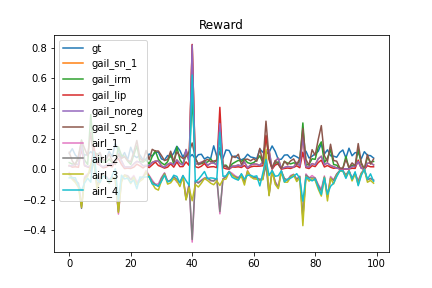

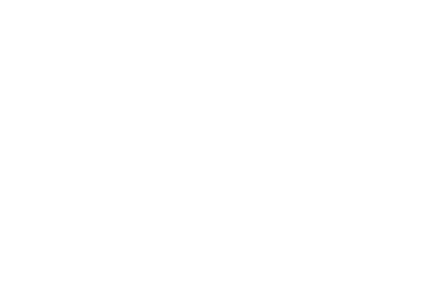

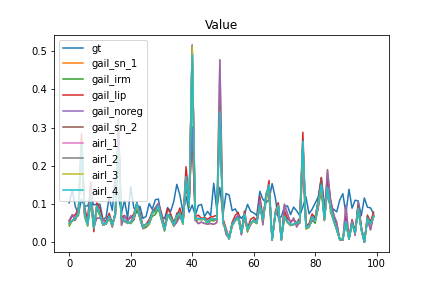

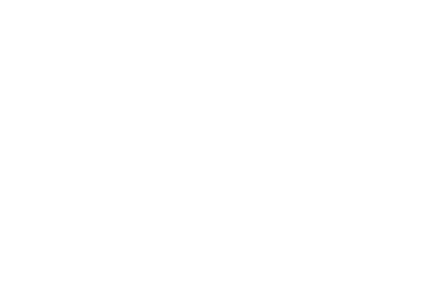

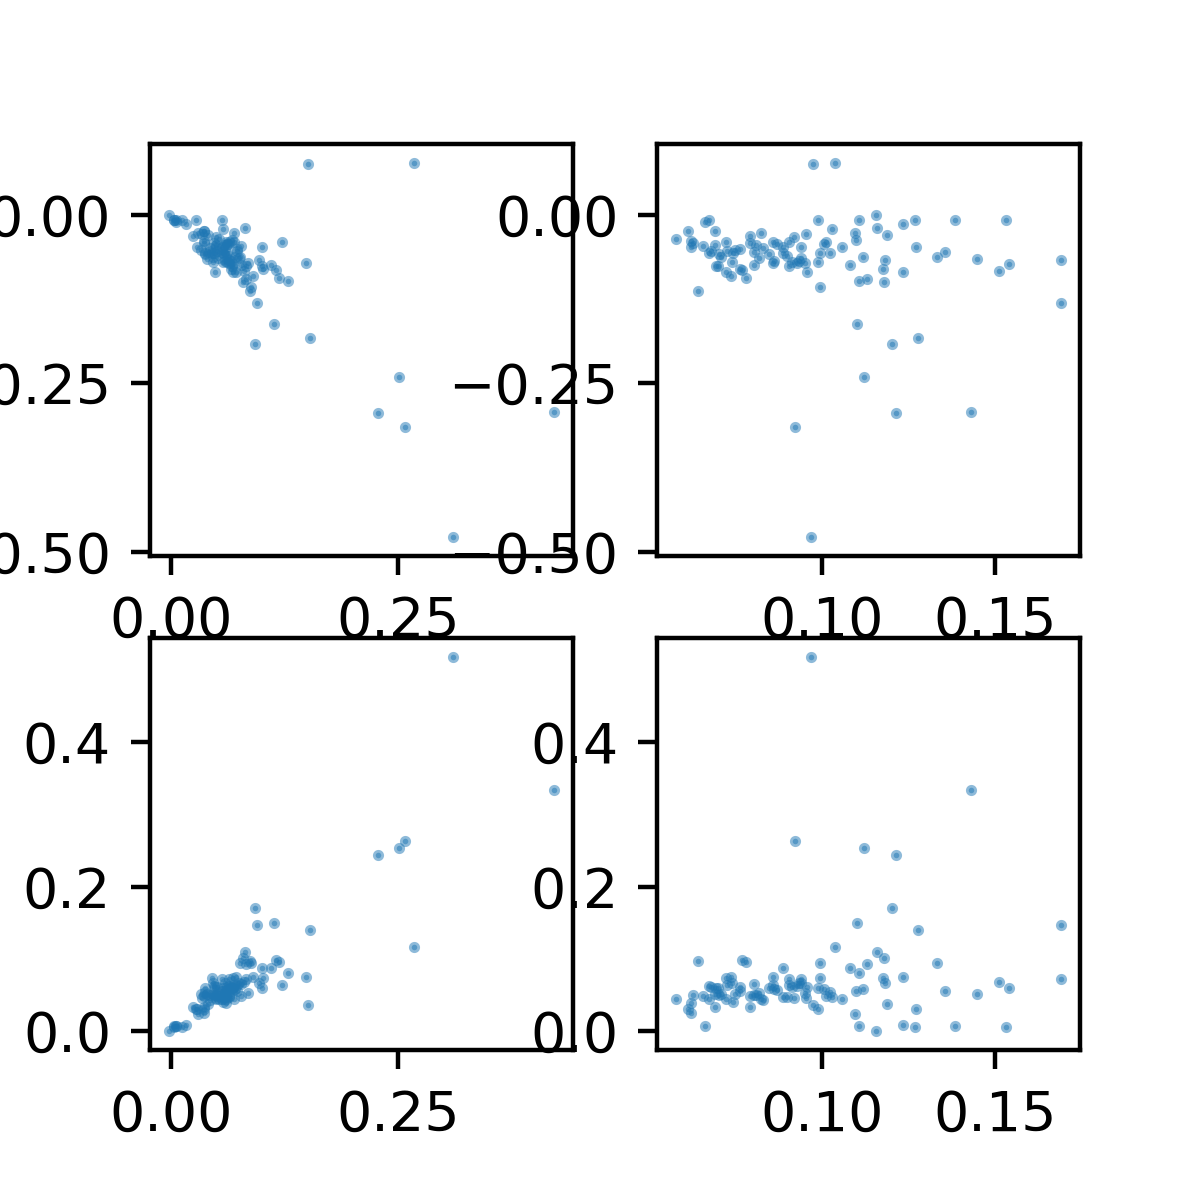

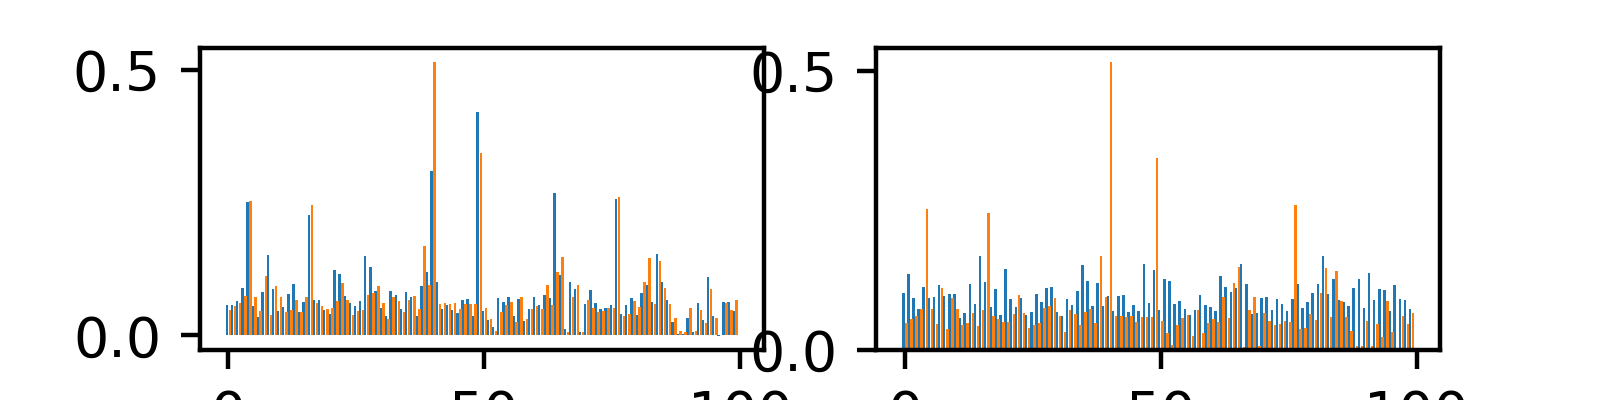

In [473]:

dist_score, safety_score, pr_sc_disc_sn, pr_sc_val_sn = eval_data_2(test_env,total_distance_score, total_safety_score, actor_sn, disc_sn, data_dict)
_,_, pr_sc_disc_irm, pr_sc_val_irm = eval_data_2(test_env,total_distance_score, total_safety_score, actor_irm, disc_irm, data_dict)
_,_, pr_sc_disc_lip, pr_sc_val_lip = eval_data_2(test_env,total_distance_score, total_safety_score, actor_lip, disc_lip, data_dict)
_,_, pr_sc_disc_noreg, pr_sc_val_noreg = eval_data_2(test_env,total_distance_score, total_safety_score,actor_noreg, disc_noreg, data_dict)
_,_, pr_sc_disc_sacairl, pr_sc_val_sacairl = eval_data_2(test_env,total_distance_score, total_safety_score, actor_sac, disc_sac, data_dict, algo_type='sac', disc_type='airl')
_,_, pr_sc_disc_ppoairl, pr_sc_val_ppoairl = eval_data_2(test_env,total_distance_score, total_safety_score, actor_airl, disc_airl, data_dict, algo_type='ppo', disc_type='airl')
_,_, pr_sc_disc_ppoairl_, pr_sc_val_ppoairl_ = eval_data_2(test_env,total_distance_score, total_safety_score,  actor_airl_, disc_airl_, data_dict, algo_type='ppo', disc_type='airl')
_,_, pr_sc_disc_ppoairl__, pr_sc_val_ppoairl__ = eval_data_2(test_env,total_distance_score, total_safety_score,  actor_airl__, disc_airl__, data_dict, algo_type='ppo', disc_type='airl')
_,_, pr_sc_disc_ppogail___, pr_sc_val_ppogail___ = eval_data_2(test_env,total_distance_score, total_safety_score,  actor_gail___, disc_gail___, data_dict, algo_type='ppo', disc_type='gail')
_,_, pr_sc_disc_ppoairl___, pr_sc_val_ppoairl___ = eval_data_2(test_env,total_distance_score, total_safety_score,  actor_airl___, disc_airl___, data_dict, algo_type='ppo', disc_type='airl')

#dist_sc = np.array(list(total_distance_score.values()))
#safety_sc = np.array(list(total_safety_score.values()))
dist_sc_normed = dist_score / np.linalg.norm(dist_score)
safety_sc_normed = safety_score / np.linalg.norm(safety_score)

#gt_score_normed = dist_sc_normed + safety_sc_normed
gt_score_normed = safety_sc_normed

%matplotlib widget
#plt.matshow(np.outer(gt_score_normed,pr_sc_val_sn))
#plt.matshow(np.outer(gt_score_normed,pr_sc_val_irm))
#plt.matshow(np.outer(gt_score_normed,pr_sc_val_lip))


# TODO: add model to tuple
disc_dict = {'gail_sn_1': pr_sc_disc_sn,
             'gail_irm': pr_sc_disc_irm,
             'gail_lip': pr_sc_disc_lip,
             'gail_noreg': pr_sc_disc_sn,
             'gail_sn_2': pr_sc_disc_ppogail___,
             'airl_1': pr_sc_disc_ppoairl,
             'airl_2': pr_sc_disc_ppoairl_,
             'airl_3': pr_sc_disc_ppoairl__,
             'airl_4': pr_sc_disc_ppoairl___,
             } 

val_dict = {'gail_sn_1': pr_sc_val_sn,
             'gail_irm': pr_sc_val_irm,
             'gail_lip': pr_sc_val_lip,
             'gail_noreg': pr_sc_val_sn,
             'gail_sn_2': pr_sc_val_ppogail___,
             'airl_1': pr_sc_val_ppoairl,
             'airl_2': pr_sc_val_ppoairl_,
             'airl_3': pr_sc_val_ppoairl__,
             'airl_4': pr_sc_val_ppoairl___,
             } 

plt.figure()
plt.plot(gt_score_normed, label='gt')
for k,v in disc_dict.items():
    plt.plot(v, label=k)

plt.title('Reward')
plt.legend()
plt.figure()

plt.figure()
plt.plot(gt_score_normed, label='gt')
for k,v in val_dict.items():
    plt.plot(v, label=k)

plt.title('Value')
plt.legend()
plt.figure()

x = np.arange(len(gt_score_normed))
#plt.scatter(x, gt_score_normed, label='gt')
#x = x-0.2
#plt.scatter(x, pr_sc_val_sn, label='val_sn')
#x = x+0.4
#plt.scatter(pr_sc_val_irm, label='val_irm')

# correlation coeffs

print(">> Discriminator scores") 

table_rows = [["Model", "Pearson CC", "Pearson p-Value", 
             "Spearman CC", "Pearson p-Value",
             "Wilcoxon CC", "Wilcoxon p-Value"]]

for gt_score_normed in [dist_sc_normed, safety_sc_normed]:
    for j, item_dict in enumerate([disc_dict, val_dict]):
        for k,v in disc_dict.items():
            #print(">> Discriminator scores") 
            pearson_cc = scipy.stats.pearsonr(gt_score_normed, v)
            spearman_cc = scipy.stats.spearmanr(gt_score_normed, v)
            kendall_cc = scipy.stats.weightedtau(gt_score_normed, v)
            wilcoxon_cc = scipy.stats.ranksums(gt_score_normed, v)
            
            if j == 0:
                name_string = " (Reward)"
            else:
                name_string = " (Value)"
            
            # TODO: add W2 / SW2 distances of respective model rollouts
            table_row = [k + name_string, pearson_cc[0], pearson_cc[1], 
                         spearman_cc[0], spearman_cc[1],
                         #kendall_cc[0], kendall_cc[1],
                         wilcoxon_cc[0], wilcoxon_cc[1]]
            
            table_rows.append(table_row)
            #print(">> Order correlation disc")
            #print(scipy.stats.pearsonr(np.argsort(gt_score_normed) , np.argsort(v)))
            #print(scipy.stats.spearmanr(np.argsort(gt_score_normed) , np.argsort(v)))
            #print(scipy.stats.kendalltau(np.argsort(gt_score_normed) , np.argsort(v)))
            #print(scipy.stats.ranksums(np.argsort(gt_score_normed) , np.argsort(v)))
            #print(">> Rank correlation disc")
            #print(scipy.stats.pearsonr(np.argsort(gt_score_normed).argsort() , np.argsort(v).argsort()))
            #print(scipy.stats.spearmanr(np.argsort(gt_score_normed).argsort() , np.argsort(v).argsort()))
            #print(scipy.stats.kendalltau(np.argsort(gt_score_normed).argsort() , np.argsort(v).argsort()))


# populate table

table_1 = Texttable()

table_1.set_cols_align(["c" for i in range(len(table_rows[0]))])
table_1.set_cols_valign(["c" for i in range(len(table_rows[0]))])
table_1.add_rows(table_rows)
print('Texttable Output:')
print(table_1.draw())
print('\nLatextable Output:')
print(latextable.draw_latex(table_1, caption="An example table.", label="table:example_table"))

### plot correlation etc

# TODO: GP correlation / covariance structure?
fig, ax = plt.subplots(2,2, figsize=(3,3), dpi=400)
ax[0,0].scatter(dist_sc_normed, pr_sc_disc_ppoairl, s=1, alpha=0.5)
ax[1,0].scatter(dist_sc_normed, pr_sc_val_ppoairl, s=1, alpha=0.5)       
ax[0,1].scatter(safety_sc_normed, pr_sc_disc_ppoairl, s=1, alpha=0.5)
ax[1,1].scatter(safety_sc_normed, pr_sc_val_ppoairl, s=1, alpha=0.5)

fig, ax =plt.subplots(1,2, figsize=(4,1), dpi=400)
ax[0].bar(np.arange(len(dist_sc_normed))-0.3, dist_sc_normed, .5)
ax[0].bar(np.arange(len(pr_sc_val_ppoairl__))+0.3, pr_sc_val_ppoairl_, .5)
ax[1].bar(np.arange(len(safety_sc_normed))-0.3, safety_sc_normed, .5)
ax[1].bar(np.arange(len(pr_sc_val_ppoairl__))+0.3, pr_sc_val_ppoairl_, .5)

print(safety_sc_normed[:10], pr_sc_val_irm[:10])
